# Bloque B: Textura, identificación y evaluación

Notebook del bloque B (`feat/texture-eval`). Todo el análisis se hace con las **máscaras del Ground Truth (GT)**.

**Contenido**

| Sección | Tarea | Qué se hace |
|---|---|---|
| 0 | Setup | Imports y rutas |
| 1 | Datos | Recortes y máscaras desde los polígonos GT |
| 2 | B1 | GLCM de cada eritrocito |
| 3 | B2 | Ranking y selección de atributos de textura (solo train) |
| 4 | B3 | Prueba de las métricas de segmentación (Dice, IoU, matching) |
| 5 | B4 | Umbrales de textura con curva ROC (solo train) |
| 6 | B5 | Estrategia combinada color + textura |
| 7 | B6 | Evaluación contra el GT |

**Reglas que se respetan en todo el notebook**
- Los umbrales, atributos y modelos se ajustan **solo con train**.
- `test` se usa **una sola vez**, al final (sección 7), sin reajustar nada.
- Las etiquetas del GT sirven para ajustar y evaluar, nunca para decidir la etiqueta de una célula de test.

## 0. Setup

Se agrega la raíz del proyecto al `sys.path` (el notebook corre desde `texture_eval/notebooks/`) y se importan las funciones de los módulos del bloque.

In [1]:
import sys
from pathlib import Path

# Raíz del proyecto: texture_eval/notebooks -> raíz
ROOT_PROY = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(ROOT_PROY))

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Funciones compartidas del grupo
from common.io_utils import cargar_subset, cargar_imagen, cargar_gt
from common.generar_gt_utils import celulas_desde_gt

# Módulos del bloque B
from texture_eval.glcm_features import glcm_celula
from texture_eval.thresholds import (ranking_atributos, seleccionar_atributos,
                                     auc_por_paciente, auc_mw, tabla_umbrales, lopo_umbral)
from texture_eval.rules_classifier import definir_estrategias, evaluar_lopo, ajustar_final, marcar
from texture_eval.seg_metrics import evaluar_imagen, mapa_gt, metricas, resumen, ponderado
from texture_eval import stats_analysis as sa

CLASES = ["Parasitized", "Uninfected"]            # sin glóbulos blancos
RESULTS = ROOT_PROY / "texture_eval" / "results"  # carpeta de salidas
RESULTS.mkdir(parents=True, exist_ok=True)

## 1. Datos: recortes y máscaras desde el GT

`celulas_desde_gt()` recorre las imágenes de `subset.csv` y, para cada polígono del GT, devuelve:
- `meta`: `cell_id` global (paciente + imagen + id local), imagen, paciente, split y etiqueta,
- `crop`: recorte RGB al rectángulo que contiene a la célula,
- `mask`: máscara binaria del eritrocito, del mismo tamaño que el recorte.

### 1.1 Inspección visual
Se grafican algunas células para comprobar que el recorte y la máscara coinciden.

{'cell_id': '208C67P28N_ThinF_IMG_20150819_115417_1-1', 'image_id': 'IMG_20150819_115417.jpg', 'patient_id': '208C67P28N_ThinF', 'split': 'train', 'label': 'Parasitized'}


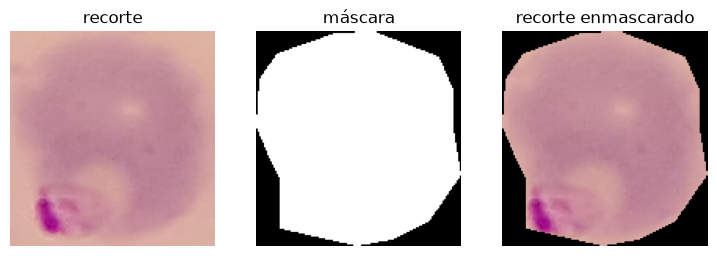

{'cell_id': '208C67P28N_ThinF_IMG_20150819_115417_1-2', 'image_id': 'IMG_20150819_115417.jpg', 'patient_id': '208C67P28N_ThinF', 'split': 'train', 'label': 'Parasitized'}


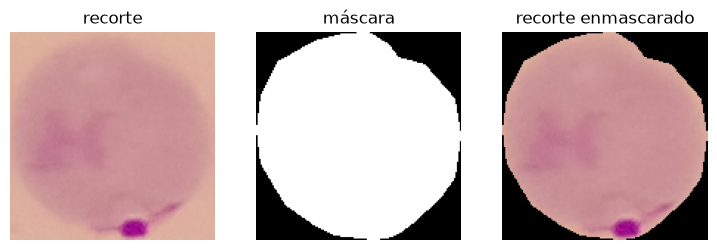

{'cell_id': '208C67P28N_ThinF_IMG_20150819_115417_1-3', 'image_id': 'IMG_20150819_115417.jpg', 'patient_id': '208C67P28N_ThinF', 'split': 'train', 'label': 'Parasitized'}


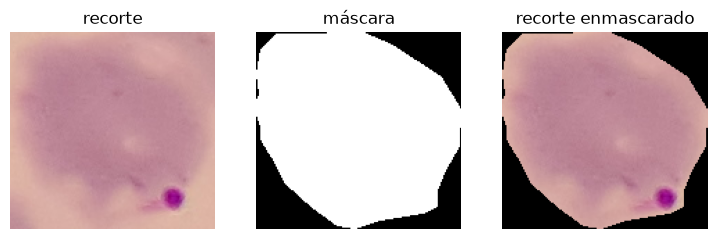

{'cell_id': '208C67P28N_ThinF_IMG_20150819_115417_1-4', 'image_id': 'IMG_20150819_115417.jpg', 'patient_id': '208C67P28N_ThinF', 'split': 'train', 'label': 'Parasitized'}


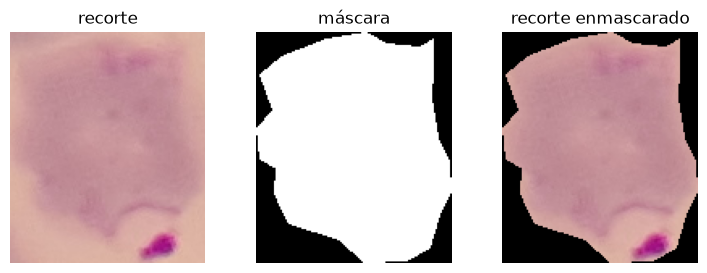

{'cell_id': '208C67P28N_ThinF_IMG_20150819_115417_1-5', 'image_id': 'IMG_20150819_115417.jpg', 'patient_id': '208C67P28N_ThinF', 'split': 'train', 'label': 'Uninfected'}


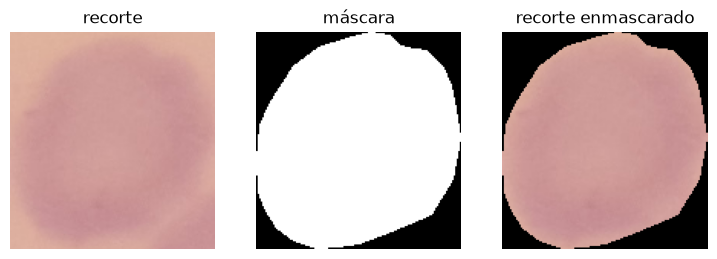

In [2]:
# Primeras 5 células: recorte, máscara y recorte enmascarado
gen = celulas_desde_gt()

for i in range(5):
    meta, crop, mask = next(gen)
    print(meta)

    fig, axs = plt.subplots(1, 3, figsize=(9, 3))
    axs[0].imshow(crop);                          axs[0].set_title("recorte")
    axs[1].imshow(mask, cmap="gray");             axs[1].set_title("máscara")
    axs[2].imshow(crop * (mask[..., None] > 0));  axs[2].set_title("recorte enmascarado")
    for ax in axs: ax.axis("off")
    plt.show()

### 1.2 ¿Qué canal tiene más contraste?
Se compara el canal rojo, verde y azul de una célula parasitada, con la misma escala (0-255) para que sean comparables. El canal con más contraste es donde se distingue mejor el parásito del citoplasma.

208C67P28N_ThinF_IMG_20150819_115417_1-1 Parasitized


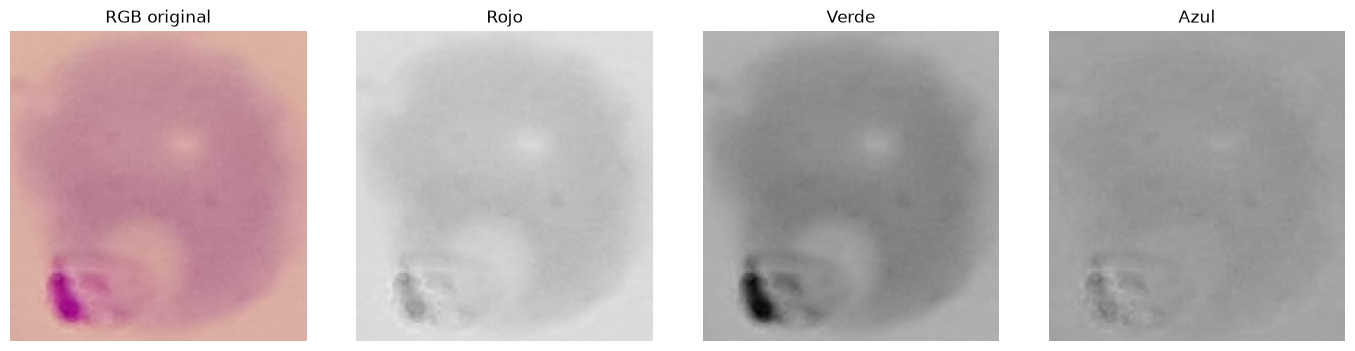

In [3]:
# Primera célula parasitada del subconjunto
for meta, crop, mask in celulas_desde_gt():
    if meta["label"] == "Parasitized":
        break
print(meta["cell_id"], meta["label"])

nombres = ["Rojo", "Verde", "Azul"]
fig, axs = plt.subplots(1, 4, figsize=(14, 3.5))

axs[0].imshow(crop)
axs[0].set_title("RGB original")

for i, nombre in enumerate(nombres):
    # vmin/vmax fijos para que los tres canales se comparen con la misma escala
    axs[i + 1].imshow(crop[:, :, i], cmap="gray", vmin=0, vmax=255)
    axs[i + 1].set_title(nombre)

for ax in axs: ax.axis("off")
plt.tight_layout()
plt.show()

## 2. B1: GLCM por eritrocito

`glcm_celula(crop, mask)` calcula la matriz de co-ocurrencia **solo con los píxeles dentro de la célula** y devuelve contraste, homogeneidad, energía, correlación y entropía (promediados sobre los 4 ángulos, para cada distancia), más `n_pixeles`.

Nota: se calcula para tanto las células de train como de test. Calcular un descriptor no ajusta nada, y así la textura de test queda lista para B6. El ajuste se hace más adelante, filtrando por `split == "train"`.

In [4]:
filas = []
for meta, crop, mask in celulas_desde_gt():
    feats = glcm_celula(crop, mask)     # descriptores de textura de la célula
    if feats is None:                   # célula sin pares válidos
        continue
    filas.append({**meta, **feats})     # metadatos + descriptores en una fila

df = pd.DataFrame(filas)
df.groupby(["split", "label"]).size()   # cantidad de células por partición y clase

split  label           
test   Parasitized           23
       Uninfected           976
       White_Blood_Cell       3
train  Parasitized          217
       Uninfected          2135
       White_Blood_Cell      10
dtype: int64

In [5]:
# Guardado (queda en results/)
df.to_csv(RESULTS / "features_texture_gt_provisorio.csv", index=False)

## 3. B2: ranking y selección de atributos (solo train)

Se trabaja únicamente con células de **train** y sin glóbulos blancos.

In [6]:
train = df[(df["split"] == "train") & (df["label"].isin(CLASES))].copy()
assert (train["split"] == "train").all()      # si se cuela algo de test, se frena acá

# Células por paciente y clase, para ver el desbalance
print(train.groupby(["patient_id", "label"]).size().unstack(fill_value=0))

# Columnas de textura: todo menos metadatos y conteos auxiliares
meta_cols = ["cell_id", "image_id", "patient_id", "split", "label", "n_pixeles", "n_pares_min"]
feat_cols = [c for c in train.columns if c not in meta_cols]
print("\nDescriptores de textura:", len(feat_cols))

label             Parasitized  Uninfected
patient_id                               
208C67P28N_ThinF           21         457
209C68P29N_ThinF          145         268
211C70P31_ThinF            37         193
212C71P32_ThinF             5         496
263C115P76ThinF             5         486
282C134P95ThinF             4         235

Descriptores de textura: 15


### 3.1 Ranking por AUC
Para cada descriptor se calcula el AUC (parasitadas vs. no infectadas) con el estadístico U de Mann-Whitney: `AUC = U / (n_parasitadas · n_no_infectadas)`. `separacion = max(AUC, 1 - AUC)` ordena sin importar el sentido (0,5 no separa nada, 1 es perfecto).

In [7]:
ranking = ranking_atributos(train, feat_cols)
display(ranking.round(4))

,feature,auc,separacion,sentido,p_value
0,contrast_d3,0.9906,0.9906,mayor en parasitadas,0.0
1,contrast_d2,0.9874,0.9874,mayor en parasitadas,0.0
2,contrast_d1,0.9821,0.9821,mayor en parasitadas,0.0
3,homogeneity_d2,0.0563,0.9437,menor en parasitadas,0.0
4,homogeneity_d1,0.0574,0.9426,menor en parasitadas,0.0
5,homogeneity_d3,0.0606,0.9394,menor en parasitadas,0.0
6,entropy_d2,0.9194,0.9194,mayor en parasitadas,0.0
7,entropy_d3,0.9193,0.9193,mayor en parasitadas,0.0
8,entropy_d1,0.9184,0.9184,mayor en parasitadas,0.0
9,correlation_d1,0.8899,0.8899,mayor en parasitadas,0.0


### 3.2 Distribución de los mejores descriptores

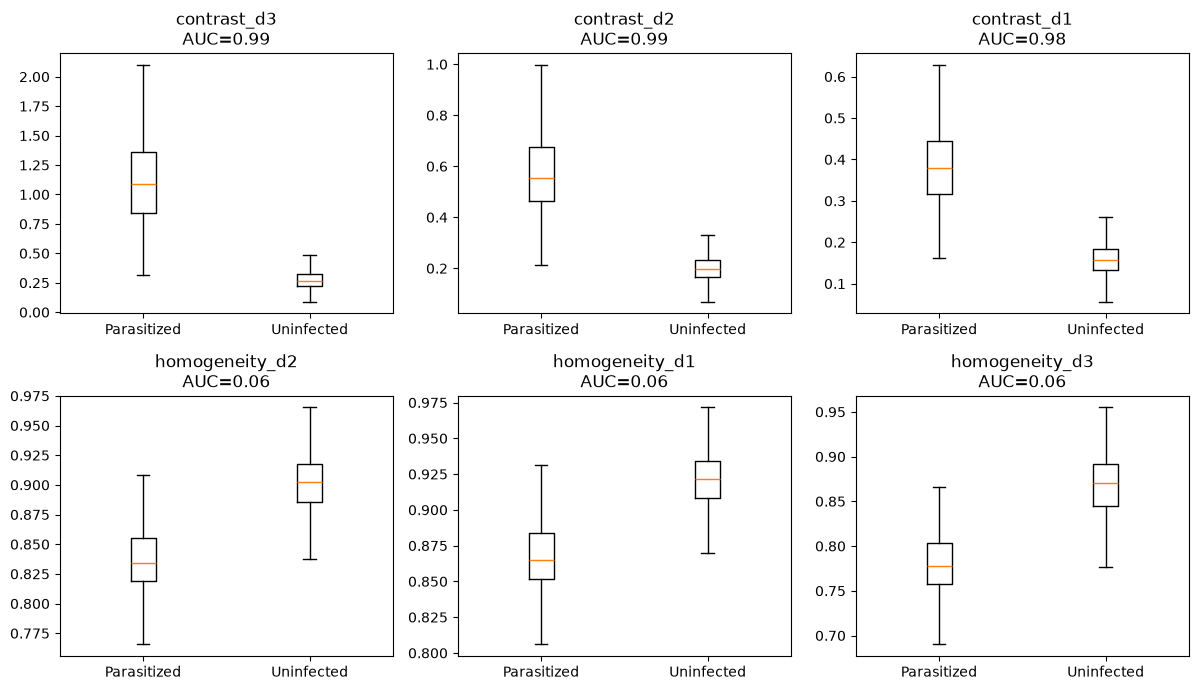

In [8]:
_ = sa.boxplots_top(train, ranking, n=6)
plt.show()

### 3.3 Consistencia entre pacientes
Un buen descriptor separa del mismo lado de 0,5 en casi todos los pacientes. Si funciona solo en uno o dos, probablemente captura diferencias de tinción. Con menos de 5 células en alguna clase, el AUC del paciente no se calcula (`NaN`).

Además se mide el AUC del **tamaño** de la célula (`n_pixeles`) como referencia: si la textura no mejora claramente ese valor, no estaría aportando.

In [9]:
top = ranking["feature"].head(6).tolist()
display(auc_por_paciente(train, top).round(2))

auc_tam, _ = auc_mw(train.loc[train.label == "Parasitized", "n_pixeles"],
                    train.loc[train.label == "Uninfected", "n_pixeles"])
print("AUC de n_pixeles (tamaño):", round(auc_tam, 3))

,contrast_d3,contrast_d2,contrast_d1,homogeneity_d2,homogeneity_d1,homogeneity_d3
208C67P28N_ThinF,1.00,0.99,0.99,0.18,0.17,0.19
209C68P29N_ThinF,0.98,0.98,0.98,0.09,0.08,0.13
211C70P31_ThinF,1.00,1.00,0.99,0.06,0.05,0.08
212C71P32_ThinF,1.00,1.00,1.00,0.06,0.06,0.04
263C115P76ThinF,0.90,0.88,0.84,0.20,0.23,0.18
282C134P95ThinF,NaN,NaN,NaN,NaN,NaN,NaN


AUC de n_pixeles (tamaño): 0.518


### 3.4 Selección sin redundancia
Se recorre el ranking de mejor a peor y se agrega cada descriptor si separa al menos `0,6` y no es casi una copia (|Spearman| < `0,9`) de uno ya elegido. Los bloques rojos o azules intensos del mapa de calor son grupos de descriptores equivalentes.

Seleccionados: ['contrast_d3', 'correlation_d1', 'energy_d1']


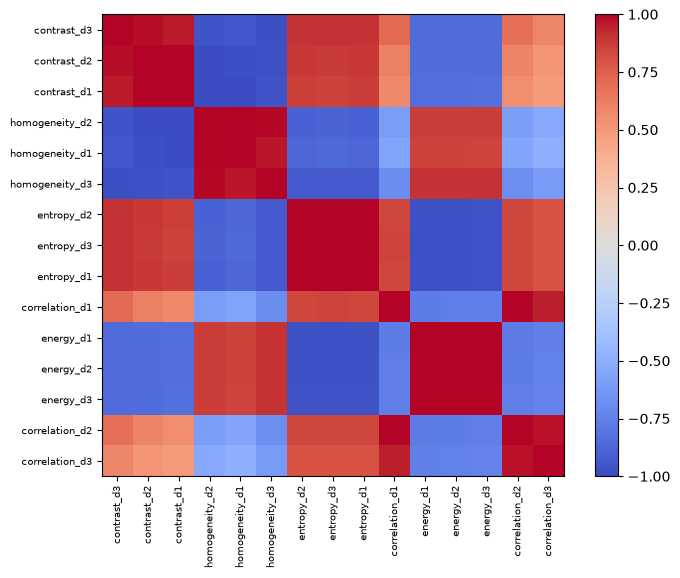

In [10]:
seleccion, corr = seleccionar_atributos(train, ranking, sep_min=0.6, rho_max=0.9)
print("Seleccionados:", seleccion)

_ = sa.heatmap_correlacion(corr)
plt.show()

In [11]:
# Guardado del ranking y la selección
ranking.to_csv(RESULTS / "b2_ranking_atributos.csv", index=False)
pd.Series(seleccion, name="feature").to_csv(RESULTS / "b2_atributos_seleccionados.csv", index=False)

## 4. B3: prueba de las métricas de segmentación

Antes de usar `evaluar_imagen` se comprueba que funciona con casos de resultado conocido, usando el GT como "predicción":

1. `pred = GT`: debe dar TP = N, FP = FN = 0, Dice = IoU = 1.
2. Bordes dilatados: el IoU baja por debajo de 1, pero los TP/FP/FN no cambian.
3. 20 células borradas: debe dar FN = 20.

In [12]:
from skimage.morphology import dilation, disk

# Imagen de prueba: la primera de train
reg = cargar_subset("train")[0]
img = cargar_imagen(reg["patient_id"], reg["image_id"])
anot, _ = cargar_gt(reg["patient_id"], reg["image_id"])
gt = mapa_gt(img.shape, anot)

# 1) pred = GT
r = evaluar_imagen(gt, gt); print({k: v for k, v in r.items() if k != "pares"})

# 2) pred con bordes dilatados
pred = dilation(gt, disk(3))
r = evaluar_imagen(gt, pred); print({k: v for k, v in r.items() if k != "pares"})

# 3) pred con 20 células borradas
pred = gt.copy()
for i in np.unique(gt)[1:21]: pred[pred == i] = 0
r = evaluar_imagen(gt, pred); print({k: v for k, v in r.items() if k != "pares"})

{'TP': 187, 'FP': 0, 'FN': 0, 'precision': 1.0, 'sensibilidad': 1.0, 'F1': 1.0, 'IoU_medio_TP': 1.0, 'Dice_medio_TP': 1.0, 'IoU_pixel': 1.0, 'Dice_pixel': 1.0}
{'TP': 187, 'FP': 0, 'FN': 0, 'precision': 1.0, 'sensibilidad': 1.0, 'F1': 1.0, 'IoU_medio_TP': 0.9156719830904391, 'Dice_medio_TP': 0.9559629279923353, 'IoU_pixel': 0.9232170628103491, 'Dice_pixel': 0.9600757820453975}
{'TP': 167, 'FP': 0, 'FN': 20, 'precision': 1.0, 'sensibilidad': 0.893048128342246, 'F1': 0.943502824858757, 'IoU_medio_TP': 1.0, 'Dice_medio_TP': 1.0, 'IoU_pixel': 0.8913985023115367, 'Dice_pixel': 0.9425813769252022}


## 5. B4: umbrales de textura con curva ROC (solo train)

### 5.1 Curvas ROC de los atributos seleccionados
Si un descriptor es menor en parasitadas, se invierte el signo para que "score alto = parasitada".

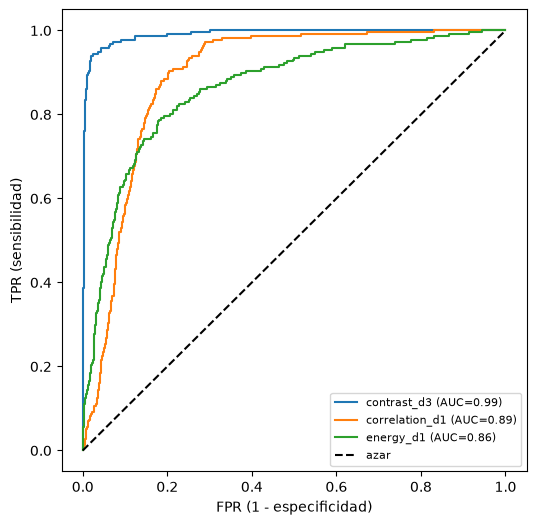

In [13]:
_ = sa.curvas_roc(train, ranking, seleccion)
plt.show()

### 5.2 Umbral óptimo de cada atributo
Dos criterios sobre todo train:
- **Youden:** maximiza sensibilidad − (1 − especificidad). Con el desbalance (~1:13) tiende a regalar falsos positivos.
- **F1:** incluye la precisión, así que es más conservador. **Es el criterio que se usa en B5 y B6.**

In [14]:
umbrales = tabla_umbrales(train, ranking, seleccion)
display(umbrales.round(3))
umbrales.to_csv(RESULTS / "b4_umbrales_textura.csv", index=False)

,feature,criterio,regla,umbral,sentido,sensibilidad,especificidad,precision,F1
0,contrast_d3,Youden,contrast_d3 >= 0.5958,0.596,1,0.940,0.981,0.833,0.883
1,contrast_d3,F1,contrast_d3 >= 0.6984,0.698,1,0.894,0.990,0.898,0.896
2,correlation_d1,Youden,correlation_d1 >= 0.9437,0.944,1,0.903,0.797,0.311,0.463
3,correlation_d1,F1,correlation_d1 >= 0.9491,0.949,1,0.797,0.851,0.352,0.489
4,energy_d1,Youden,energy_d1 <= 0.4176,0.418,-1,0.788,0.821,0.309,0.444
5,energy_d1,F1,energy_d1 <= 0.3814,0.381,-1,0.627,0.911,0.418,0.502


### 5.3 Validación leave-one-patient-out
El umbral se ajusta con 5 pacientes y se prueba en el que quedó afuera. Muestra si el umbral es estable entre pacientes y da métricas menos optimistas que las de la tabla anterior (que usan los mismos datos para ajustar y evaluar).

In [15]:
loo_b4 = lopo_umbral(train, ranking, seleccion, criterio="F1")

# ¿Es estable el umbral entre pacientes?
display(loo_b4.pivot(index="paciente_fuera", columns="feature", values="umbral").round(3))

# Métricas acumuladas sumando los pacientes dejados afuera
res_b4 = resumen(loo_b4, "feature")
display(res_b4.round(3))

feature,contrast_d3,correlation_d1,energy_d1
paciente_fuera,,,
208C67P28N_ThinF,0.698,0.951,0.381
209C68P29N_ThinF,0.665,0.958,0.395
211C70P31_ThinF,0.713,0.948,0.379
212C71P32_ThinF,0.710,0.951,0.381
263C115P76ThinF,0.698,0.949,0.381
282C134P95ThinF,0.698,0.949,0.381


,TP,FP,FN,precision,sensibilidad,F1
feature,,,,,,
contrast_d3,192,25,25,0.885,0.885,0.885
correlation_d1,110,252,107,0.304,0.507,0.380
energy_d1,143,228,74,0.385,0.659,0.486


## 6. B5: estrategia combinada color + textura

### 6.1 Unión con las características de color (Bloque C)
Se unen por `cell_id` las características de color de C con las de textura. `features_color_gt.csv` contiene **solo train**, así que la tabla `m` queda restringida a train por construcción.

Necesita los archivos `features_color_gt.csv` y `c4_ranking_color.csv` en `color_stain/results/`.

In [16]:
color = pd.read_csv(ROOT_PROY / "color_stain" / "results" / "features_color_gt.csv")
rank_c = pd.read_csv(ROOT_PROY / "color_stain" / "results" / "c4_ranking_color.csv")

sel_color = rank_c.loc[rank_c["seleccionada"], "caracteristica"].tolist()   # seleccionadas por C
sel_tex = list(seleccion)                                                   # seleccionadas en B2

# Color (sin n_pixeles, que ya está en textura) + textura
cols_tex = ["cell_id"] + feat_cols
m = color.drop(columns=["n_pixeles"]).merge(df[cols_tex], on="cell_id", how="inner")
m = m[m["label"].isin(CLASES)].reset_index(drop=True)
m["y"] = (m["label"] == "Parasitized").astype(int)       # 1 = parasitada
assert (m["split"] == "train").all()

print(f"color: {len(color)} | textura (train): {(df.split == 'train').sum()} | unidas: {len(m)}")
print("Color:", sel_color)
print("Textura:", sel_tex)

# Células por paciente y clase: con 4-5 parasitadas el F1 por paciente no es confiable
conteo = m.groupby(["patient_id", "label"]).size().unstack(fill_value=0)
display(conteo)

color: 2362 | textura (train): 2362 | unidas: 2352
Color: ['b_rel_p1', 'contraste_G_mancha', 'a_p95']
Textura: ['contrast_d3', 'correlation_d1', 'energy_d1']


label,Parasitized,Uninfected
patient_id,,
208C67P28N_ThinF,21,457
209C68P29N_ThinF,145,268
211C70P31_ThinF,37,193
212C71P32_ThinF,5,496
263C115P76ThinF,5,486
282C134P95ThinF,4,235


### 6.2 Estrategias evaluadas con leave-one-patient-out
Se comparan reglas de un atributo (color, textura), combinaciones AND/OR y regresiones logísticas (color, textura, color + textura). En cada vuelta, sentido, umbrales y modelos se ajustan con 5 pacientes y se prueban en el que quedó afuera. El umbral se elige por F1.

In [17]:
estrategias = definir_estrategias(sel_color, sel_tex)
loo, res = evaluar_lopo(m, estrategias)
display(res.round(3))

,TP,FP,FN,precision,sensibilidad,F1
estrategia,,,,,,
Color (b_rel_p1),167,42,50,0.799,0.770,0.784
Textura (contrast_d3),192,25,25,0.885,0.885,0.885
Color AND textura,154,10,63,0.939,0.710,0.808
Color OR textura,205,57,12,0.782,0.945,0.856
Logística color,175,19,42,0.902,0.806,0.852
Logística textura,192,28,25,0.873,0.885,0.879
Logística color+textura,198,21,19,0.904,0.912,0.908


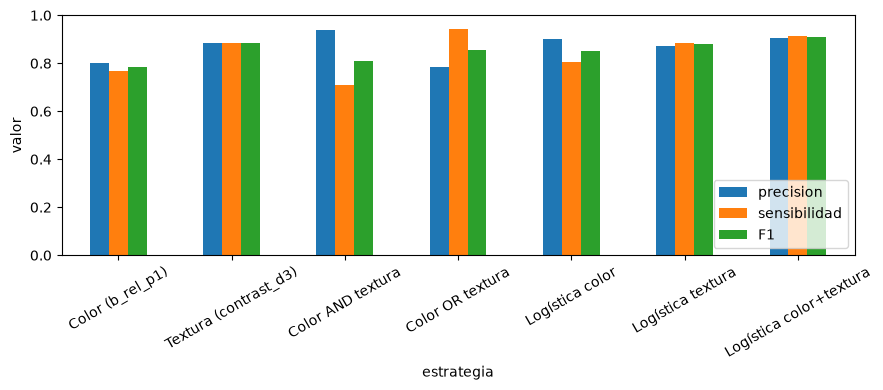

In [18]:
_ = sa.barras_estrategias(res)
plt.show()

### 6.3 F1 por paciente
Se agrega la cantidad de parasitadas de cada paciente. Los pacientes con muy pocas tienen F1 muy ruidosos (un solo error mueve mucho el valor), y las conclusiones deben apoyarse en las métricas agrupadas.

In [19]:
f1_pac = loo.pivot(index="paciente", columns="estrategia", values="F1")[list(estrategias)]
f1_pac.insert(0, "n_parasitadas", conteo["Parasitized"])
display(f1_pac.round(2))

estrategia,n_parasitadas,Color (b_rel_p1),Textura (contrast_d3),Color AND textura,Color OR textura,Logística color,Logística textura,Logística color+textura
paciente,,,,,,,,
208C67P28N_ThinF,21,0.75,0.93,0.93,0.75,0.93,0.93,0.89
209C68P29N_ThinF,145,0.80,0.92,0.80,0.91,0.89,0.91,0.97
211C70P31_ThinF,37,0.95,0.88,0.88,0.95,0.85,0.87,0.93
212C71P32_ThinF,5,0.53,0.67,0.75,0.50,0.67,0.80,0.62
263C115P76ThinF,5,0.30,0.00,0.00,0.30,0.00,0.00,0.00
282C134P95ThinF,4,0.86,0.86,0.86,0.86,1.00,0.86,0.40


In [20]:
# Guardado de los resultados de B5
res.round(4).to_csv(RESULTS / "b5_estrategias_resumen.csv")
loo.to_csv(RESULTS / "b5_estrategias_por_paciente.csv", index=False)
f1_pac.round(4).to_csv(RESULTS / "b5_f1_por_paciente.csv")

## 7. B6: evaluación contra el GT

Se comparan los métodos que parten de la **segmentación general + identificación** (color, textura, color + textura) contra el GT de células parasitadas, con el matching uno a uno de `seg_metrics` (IoU ≥ 0,5). La cuarta estrategia (segmentación dirigida por color) la entrega A en A6.

**Importante:** por ahora la "segmentación" es el propio GT, así que solo se evalúa la etapa de clasificación. Con `SPLIT = "train"` los números son **optimistas** (el modelo se ajustó con esas mismas células) y sirven para verificar el código. Los valores a reportar son los de `SPLIT = "test"`, que se corre **una sola vez** al final.

### 7.1 Modelos finales
Cada modelo se ajusta una sola vez con todas las células de train: regresión logística y umbral de probabilidad por F1.

In [21]:
METODOS = {
    "General + color":         ajustar_final(m, sel_color),
    "General + textura":       ajustar_final(m, sel_tex),
    "General + color+textura": ajustar_final(m, sel_color + sel_tex),
}

### 7.2 Tabla de células a evaluar
`SPLIT = "train"` es para desarrollo. Con `"test"` se necesita `features_color_gt_test.csv`, que tiene que generar C con las mismas funciones y parámetros (sin reajustar).

In [22]:
SPLIT = "train"      # cambiar a "test" UNA sola vez, al final

if SPLIT == "train":
    tabla = m.copy()
else:
    ruta_color_test = ROOT_PROY / "color_stain" / "results" / "features_color_gt_test.csv"
    assert ruta_color_test.exists(), "Falta features_color de test: lo genera C con los mismos parámetros"
    color_t = pd.read_csv(ruta_color_test)
    tabla = color_t.drop(columns=["n_pixeles"]).merge(df[cols_tex], on="cell_id", how="inner")
    tabla = tabla[tabla["label"].isin(CLASES)].reset_index(drop=True)

# Si algo de otro split se cuela, el notebook se frena
assert (tabla["split"] == SPLIT).all(), "La tabla tiene células de otro split"

### 7.3 Matching contra el GT por imagen
Para cada imagen se arma el mapa de etiquetas del GT (solo parasitadas) y el de la predicción (solo las células que el método marcó como parasitadas), y se evalúa con `evaluar_imagen`. Las imágenes y el GT se leen una sola vez (caché).

`mapa_pred_gt` es provisoria: dibuja los polígonos GT de las células marcadas. Cuando A entregue la segmentación propia, se reemplaza por el mapa de etiquetas de `cells_pred.csv`.

In [24]:
import time
import texture_eval.seg_metrics as sm
print("seg_metrics cargado desde:", sm.__file__)
print("¿versión rápida?", hasattr(sm, "_interseccion"))

seg_metrics cargado desde: /Users/emanuel/Documents/TPI_MALARIA/texture_eval/seg_metrics.py
¿versión rápida? False


In [23]:
# Caché: se leen imagen y GT una sola vez por imagen (no una vez por método)
cache = {}
for reg in cargar_subset(SPLIT):
    pid, iid = reg["patient_id"], reg["image_id"]
    img = cargar_imagen(pid, iid)
    anot, _ = cargar_gt(pid, iid)
    cache[(pid, iid)] = {
        "shape": img.shape,
        "anot": anot,
        "gt": mapa_gt(img.shape, anot, clases=["Parasitized"]),   # GT: solo parasitadas
    }


def mapa_pred_gt(shape, anotaciones, pid, iid, ids_marcados):
    # Mapa de etiquetas provisorio: dibuja solo las células marcadas como parasitadas
    lab = np.zeros(shape[:2], np.int32)
    for k, a in enumerate(anotaciones, start=1):
        cid = f"{pid}_{Path(iid).stem}_{a['cell_id']}"      # mismo cell_id que en B1
        if cid in ids_marcados:
            cv2.fillPoly(lab, [np.round(a["polygon"]).astype(np.int32)], k)
    return lab


def evaluar_metodo_detalle(tabla, M):
    # Una fila por imagen con TP/FP/FN contra el GT de parasitadas
    marcadas = marcar(tabla, M)                              # cell_id marcados como parasitadas
    filas = []
    for (pid, iid), c in cache.items():
        pred = mapa_pred_gt(c["shape"], c["anot"], pid, iid, marcadas)
        r = evaluar_imagen(c["gt"], pred)                    # matching + métricas
        filas.append({"paciente": pid, "imagen": iid,
                      "TP": r["TP"], "FP": r["FP"], "FN": r["FN"],
                      "IoU_medio_TP": r["IoU_medio_TP"], "Dice_medio_TP": r["Dice_medio_TP"]})
    return pd.DataFrame(filas)


# Un resultado por método, todos contra el mismo GT y el mismo umbral de IoU (0,5)
detalle = {nombre: evaluar_metodo_detalle(tabla, M) for nombre, M in METODOS.items()}

KeyboardInterrupt: 

### 7.4 Resultados
- **Total:** se suman TP/FP/FN de todas las imágenes y se recalculan precisión, sensibilidad y F1 (micro-promedio). No se promedian los F1 de cada imagen.
- **IoU y Dice medios:** promedio por imagen ponderado por TP, ignorando las imágenes sin TP.
- **Por paciente:** con 4-5 parasitadas el F1 por paciente no es confiable.

In [ ]:
total = pd.DataFrame({n: metricas(d) for n, d in detalle.items()}).T
total["IoU_medio"] = [ponderado(d, "IoU_medio_TP") for d in detalle.values()]
total["Dice_medio"] = [ponderado(d, "Dice_medio_TP") for d in detalle.values()]
display(total.round(3))

por_pac = pd.concat({n: resumen(d, "paciente") for n, d in detalle.items()})
display(por_pac.round(3))

In [ ]:
_ = sa.barras_estrategias(total)
plt.show()

total.round(4).to_csv(RESULTS / f"b6_total_{SPLIT}.csv")
por_pac.round(4).to_csv(RESULTS / f"b6_por_paciente_{SPLIT}.csv")

## Limitaciones y próximos pasos

- **Segmentación provisoria:** todo se evaluó con máscaras GT, que son limpias. Con la segmentación de A los contornos serán menos precisos y los descriptores de textura pueden cambiar; hay que repetir el análisis con `cells_pred.csv`.
- **Pocas parasitadas por paciente:** tres de los seis pacientes de train tienen 4 o 5 células parasitadas, y los resultados agrupados están dominados por los otros tres.
- **Selección de atributos:** el ranking y la selección usan todos los pacientes de train; el leave-one-patient-out solo reajusta umbrales y modelos, por lo que sus métricas son algo optimistas.
- **Pendiente con otros bloques:**
  - A: formato de `cells_pred.csv` con la posición de cada célula (o mapa de etiquetas por imagen) y la segmentación dirigida por color (A6).
  - C: `features_color` de test calculado con los mismos parámetros.
- **Evaluación final:** cambiar `SPLIT = "test"` y correr la sección 7 una sola vez, sin tocar umbrales ni modelos.